In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.preprocessing import MinMaxScaler, StandardScaler

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))
df.columns = df.columns.str.lower().str.strip()
print(df.head())

Saving weatherAUS.csv to weatherAUS (2).csv
         date location  mintemp  maxtemp  rainfall  evaporation  sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  windgustdir  windgustspeed winddir9am  ... humidity9am  humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   pressure9am  pressure3pm  cloud9am  cloud3pm  temp9

## Q1: Display First 10 Rows

In [ ]:
display(df.head(10))

,date,location,mintemp,maxtemp,rainfall,evaporation,sunshine,windgustdir,windgustspeed,winddir9am,...,humidity9am,humidity3pm,pressure9am,pressure3pm,cloud9am,cloud3pm,temp9am,temp3pm,raintoday,raintomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
5,2008-12-06,Albury,14.6,29.7,0.2,NaN,NaN,WNW,56.0,W,...,55.0,23.0,1009.2,1005.4,NaN,NaN,20.6,28.9,No,No
6,2008-12-07,Albury,14.3,25.0,0.0,NaN,NaN,W,50.0,SW,...,49.0,19.0,1009.6,1008.2,1.0,NaN,18.1,24.6,No,No
7,2008-12-08,Albury,7.7,26.7,0.0,NaN,NaN,W,35.0,SSE,...,48.0,19.0,1013.4,1010.1,NaN,NaN,16.3,25.5,No,No
8,2008-12-09,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No,Yes
9,2008-12-10,Albury,13.1,30.1,1.4,NaN,NaN,W,28.0,S,...,58.0,27.0,1007.0,1005.7,NaN,NaN,20.1,28.2,Yes,No


## Q2: Dimensions

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 145460
Columns: 23


## Q3: Print Column Names

In [ ]:
print(df.columns.tolist())

['date', 'location', 'mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine', 'windgustdir', 'windgustspeed', 'winddir9am', 'winddir3pm', 'windspeed9am', 'windspeed3pm', 'humidity9am', 'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9am', 'cloud3pm', 'temp9am', 'temp3pm', 'raintoday', 'raintomorrow']


## Q4: Data Types

In [ ]:
print(df.dtypes)

date              object
location          object
mintemp          float64
maxtemp          float64
rainfall         float64
evaporation      float64
sunshine         float64
windgustdir       object
windgustspeed    float64
winddir9am        object
winddir3pm        object
windspeed9am     float64
windspeed3pm     float64
humidity9am      float64
humidity3pm      float64
pressure9am      float64
pressure3pm      float64
cloud9am         float64
cloud3pm         float64
temp9am          float64
temp3pm          float64
raintoday         object
raintomorrow      object
dtype: object


## Q5: Missing Values Count

In [ ]:
print(df.isnull().sum())

date                 0
location             0
mintemp           1485
maxtemp           1261
rainfall          3261
evaporation      62790
sunshine         69835
windgustdir      10326
windgustspeed    10263
winddir9am       10566
winddir3pm        4228
windspeed9am      1767
windspeed3pm      3062
humidity9am       2654
humidity3pm       4507
pressure9am      15065
pressure3pm      15028
cloud9am         55888
cloud3pm         59358
temp9am           1767
temp3pm           3609
raintoday         3261
raintomorrow      3267
dtype: int64


## Q6: Rainfall Descriptive Statistics

In [ ]:
print("Mean:", df['rainfall'].mean())
print("Median:", df['rainfall'].median())
print("Std Dev:", df['rainfall'].std())

Mean: 2.3609181499166656
Median: 0.0
Std Dev: 8.478059737721674


## Q7: Temperature Extremes

In [ ]:
corr = df.select_dtypes(include='number').corr()
print(corr)

                mintemp   maxtemp  rainfall  evaporation  sunshine  \
mintemp        1.000000  0.736555  0.103938     0.466993  0.072586   
maxtemp        0.736555  1.000000 -0.074992     0.587932  0.470156   
rainfall       0.103938 -0.074992  1.000000    -0.064351 -0.227549   
evaporation    0.466993  0.587932 -0.064351     1.000000  0.365602   
sunshine       0.072586  0.470156 -0.227549     0.365602  1.000000   
windgustspeed  0.177415  0.067615  0.133659     0.203021 -0.034750   
windspeed9am   0.175064  0.014450  0.087338     0.193084  0.005499   
windspeed3pm   0.175173  0.050300  0.057887     0.129400  0.053834   
humidity9am   -0.232899 -0.504110  0.224405    -0.504092 -0.490819   
humidity3pm    0.006089 -0.508855  0.255755    -0.390243 -0.629130   
pressure9am   -0.450970 -0.332061 -0.168154    -0.270362  0.041970   
pressure3pm   -0.461292 -0.427167 -0.126534    -0.293581 -0.019719   
cloud9am       0.078754 -0.289370  0.198528    -0.183793 -0.675323   
cloud3pm       0.021

## Q9 & Q10: Correlation Heatmap

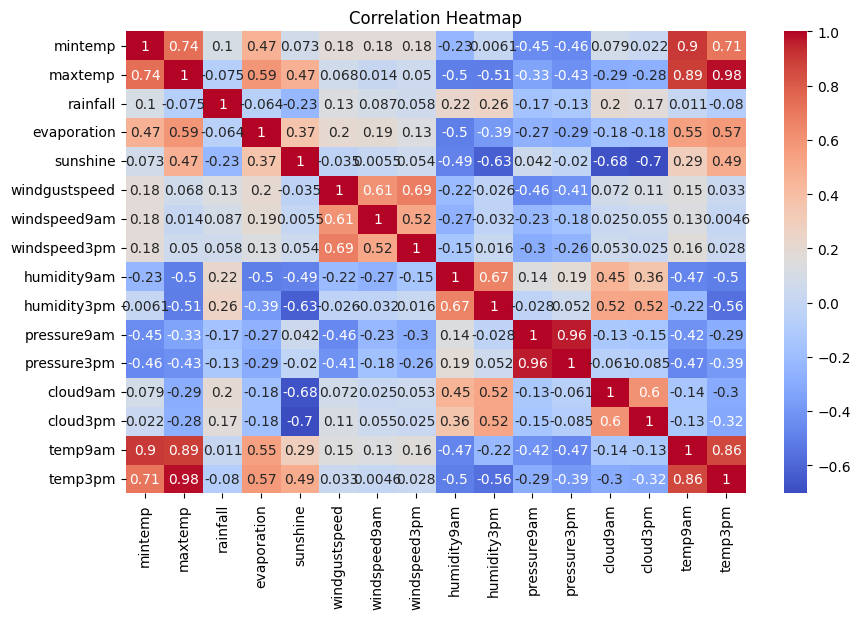

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

## Q11: Feature Correlation Sorted by Target

In [ ]:
print(corr['rainfall'].sort_values(ascending=False))

pairs = []
cols = corr.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if abs(corr.iloc[i, j]) > 0.7:
            pairs.append((cols[i], cols[j]))
print("Highly correlated pairs:", pairs)

rainfall         1.000000
humidity3pm      0.255755
humidity9am      0.224405
cloud9am         0.198528
cloud3pm         0.172403
windgustspeed    0.133659
mintemp          0.103938
windspeed9am     0.087338
windspeed3pm     0.057887
temp9am          0.011192
evaporation     -0.064351
maxtemp         -0.074992
temp3pm         -0.079657
pressure3pm     -0.126534
pressure9am     -0.168154
sunshine        -0.227549
Name: rainfall, dtype: float64
Highly correlated pairs: [('mintemp', 'maxtemp'), ('mintemp', 'temp9am'), ('mintemp', 'temp3pm'), ('maxtemp', 'temp9am'), ('maxtemp', 'temp3pm'), ('sunshine', 'cloud3pm'), ('pressure9am', 'pressure3pm'), ('temp9am', 'temp3pm')]


## Q14: Drop Highly Correlated Features

In [ ]:
drop_cols = list(set(pair[1] for pair in pairs if pair[1] != 'rainfall'))
df_reduced = df.drop(columns=drop_cols, errors='ignore')
print("Remaining columns:", df_reduced.columns.tolist())

Remaining columns: ['date', 'location', 'mintemp', 'rainfall', 'evaporation', 'sunshine', 'windgustdir', 'windgustspeed', 'winddir9am', 'winddir3pm', 'windspeed9am', 'windspeed3pm', 'humidity9am', 'humidity3pm', 'pressure9am', 'cloud9am', 'raintoday', 'raintomorrow']


## Q15: Rainfall vs Humidity Scatter Plot

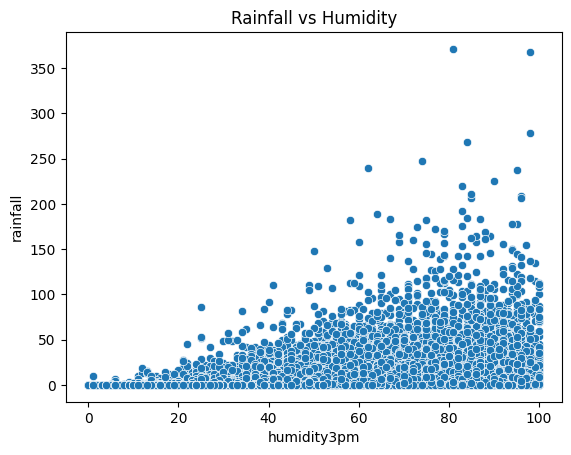

In [ ]:
sns.scatterplot(data=df, x='humidity3pm', y='rainfall')
plt.title("Rainfall vs Humidity")
plt.show()

## Q16: Histograms for All Numerical Features

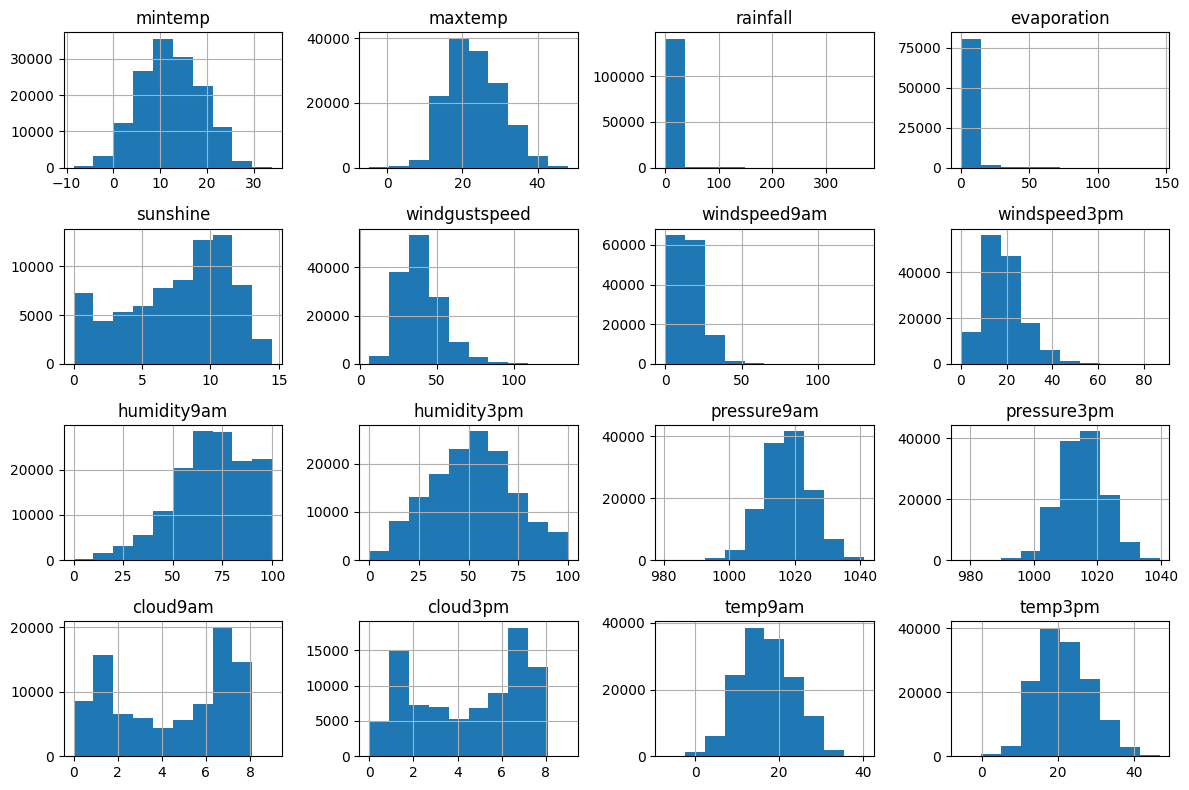

In [ ]:
df.select_dtypes(include='number').hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

## Q17: Rainfall Histogram

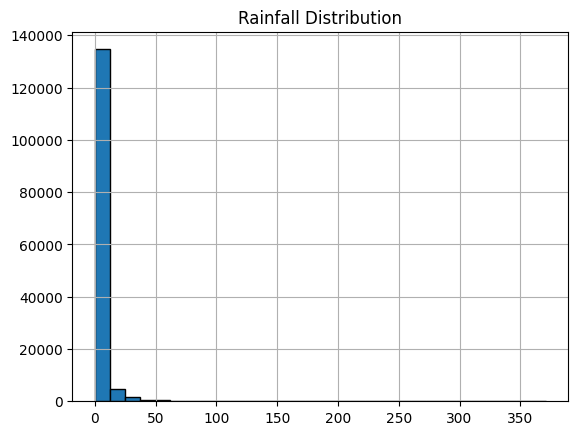

In [ ]:
df['rainfall'].hist(bins=30, edgecolor='black')
plt.title("Rainfall Distribution")
plt.show()

## Q18: Boxplots for Numerical Columns

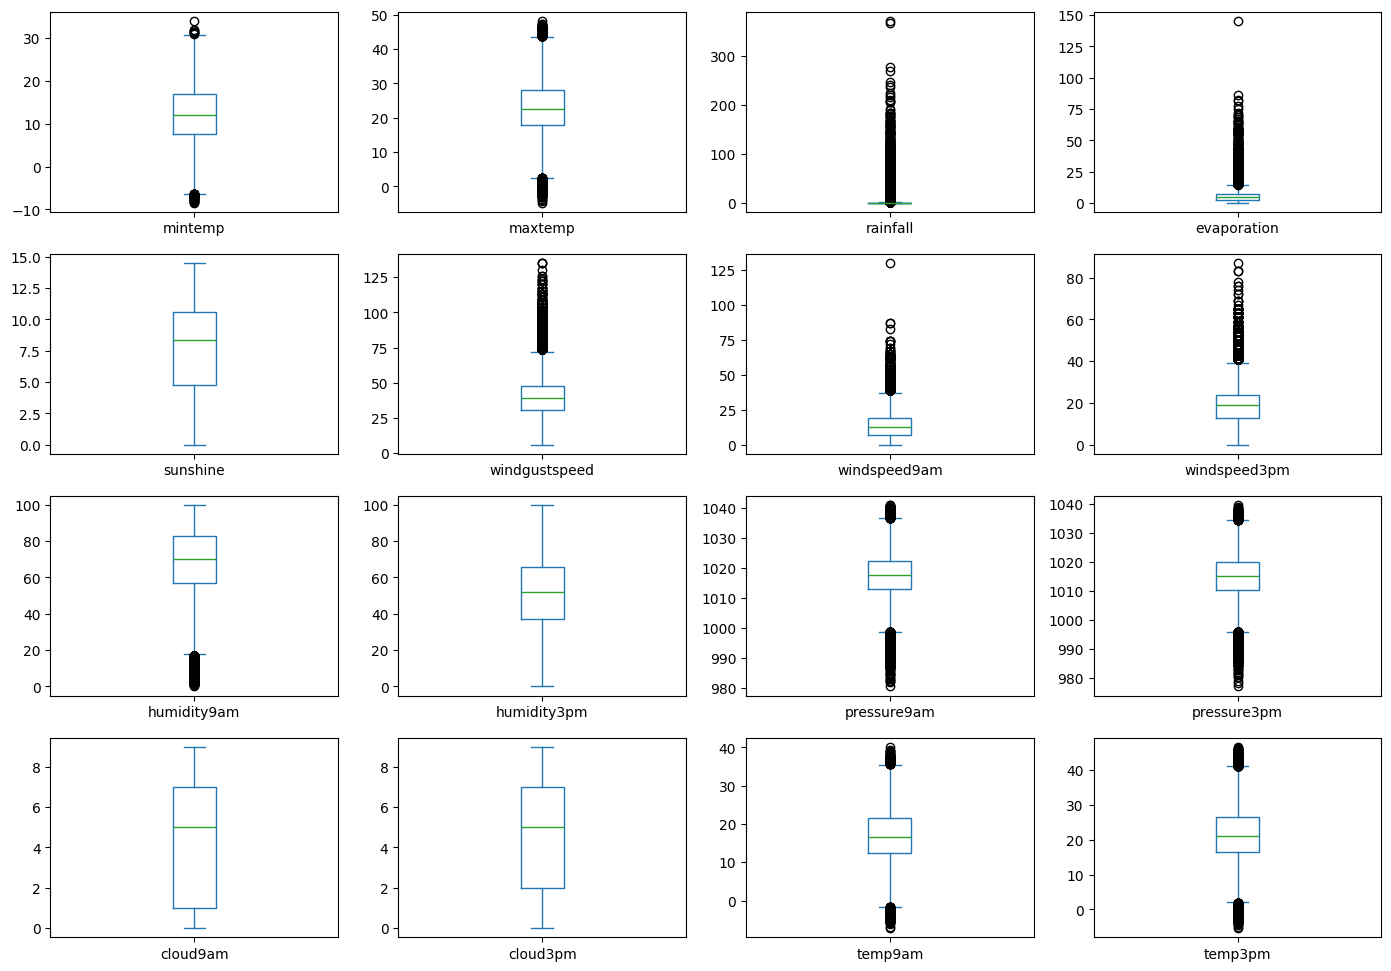

In [ ]:
df.select_dtypes(include='number').plot(kind='box', subplots=True, layout=(5, 4), figsize=(14, 12), sharex=False, sharey=False)
plt.tight_layout()
plt.show()

## Q19: Outliers Identification via IQR

In [ ]:
print(df.select_dtypes(include='number').skew())

mintemp          0.021188
maxtemp          0.220839
rainfall         9.836225
evaporation      3.761286
sunshine        -0.496480
windgustspeed    0.874879
windspeed9am     0.777630
windspeed3pm     0.628215
humidity9am     -0.483969
humidity3pm      0.033614
pressure9am     -0.095524
pressure3pm     -0.045621
cloud9am        -0.229082
cloud3pm        -0.226384
temp9am          0.088540
temp3pm          0.237960
dtype: float64


## Q21: Temperature KDE Plot

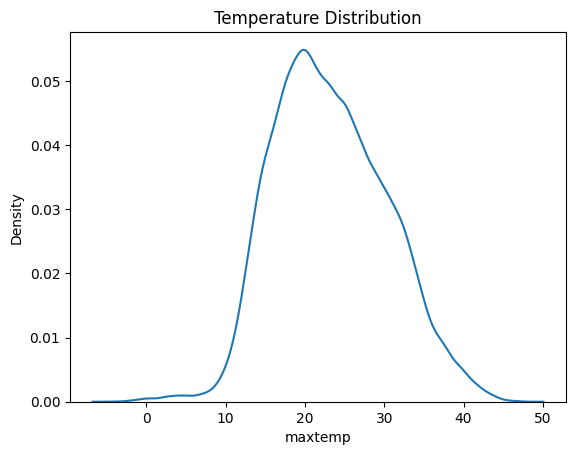

In [ ]:
sns.kdeplot(data=df, x='maxtemp')
plt.title("Temperature Distribution")
plt.show()

## Q22: Compare Rainfall Mean and Median

In [ ]:
print("Mean:", df['rainfall'].mean())
print("Median:", df['rainfall'].median())

Mean: 2.3609181499166656
Median: 0.0


## Q23: Count Positive Skewed Features

In [ ]:
skewness = df.select_dtypes(include='number').skew()
print("Right-skewed features:", (skewness > 0).sum())

Right-skewed features: 10


## Q24: Average Rainfall by Weather Condition

In [ ]:
if 'raintoday' in df.columns:
    print(df.groupby('raintoday')['rainfall'].mean())
else:
    print("Weather condition column not found")

raintoday
No      0.075248
Yes    10.270354
Name: rainfall, dtype: float64


## Q25: Top 3 Highest Rainfall Records

In [ ]:
display(df[df['rainfall'] > df['rainfall'].mean()].head())

,date,location,mintemp,maxtemp,rainfall,evaporation,sunshine,windgustdir,windgustspeed,winddir9am,...,humidity9am,humidity3pm,pressure9am,pressure3pm,cloud9am,cloud3pm,temp9am,temp3pm,raintoday,raintomorrow
12,2008-12-13,Albury,15.9,18.6,15.6,NaN,NaN,W,61.0,NNW,...,76.0,93.0,994.3,993.0,8.0,8.0,17.4,15.8,Yes,Yes
13,2008-12-14,Albury,12.6,21.0,3.6,NaN,NaN,SW,44.0,W,...,65.0,43.0,1001.2,1001.8,NaN,7.0,15.8,19.8,Yes,No
17,2008-12-18,Albury,13.5,22.9,16.8,NaN,NaN,W,63.0,N,...,80.0,65.0,1005.8,1002.2,8.0,1.0,18.0,21.5,Yes,Yes
18,2008-12-19,Albury,11.2,22.5,10.6,NaN,NaN,SSE,43.0,WSW,...,47.0,32.0,1009.4,1009.7,NaN,2.0,15.5,21.0,Yes,No
53,2009-01-23,Albury,18.8,35.2,6.4,NaN,NaN,WNW,52.0,S,...,43.0,28.0,1007.9,1003.9,NaN,NaN,22.8,33.0,Yes,No


## Q27: Temperature Comparison for High vs Low Rainfall

In [ ]:
avg_val = df['rainfall'].mean()
df['high_rainfall'] = (df['rainfall'] > avg_val).astype(int)
print(df[['rainfall', 'high_rainfall']].head())

   rainfall  high_rainfall
0       0.6              0
1       0.0              0
2       0.0              0
3       0.0              0
4       1.0              0


## Q29: High/Low Rainfall Count

In [ ]:
print(df['high_rainfall'].value_counts())

high_rainfall
0    120885
1     24575
Name: count, dtype: int64


## Q30: Correlation within High Rainfall Records

In [ ]:
high_df = df[df['high_rainfall'] == 1]
print(high_df.select_dtypes(include='number').corr())

                mintemp   maxtemp  rainfall  evaporation  sunshine  \
mintemp        1.000000  0.875603  0.208734     0.345188 -0.045520   
maxtemp        0.875603  1.000000  0.132362     0.387412  0.224302   
rainfall       0.208734  0.132362  1.000000     0.143668 -0.175821   
evaporation    0.345188  0.387412  0.143668     1.000000  0.146567   
sunshine      -0.045520  0.224302 -0.175821     0.146567  1.000000   
windgustspeed -0.080264 -0.149489  0.113683     0.095002  0.007819   
windspeed9am  -0.032443 -0.143526  0.079206     0.071590  0.001380   
windspeed3pm  -0.006170 -0.058981  0.038230     0.064624  0.116071   
humidity9am   -0.067497 -0.201924  0.137649    -0.195735 -0.503755   
humidity3pm    0.038604 -0.266259  0.172286    -0.173563 -0.656354   
pressure9am   -0.195510 -0.161115 -0.150283    -0.140067  0.029619   
pressure3pm   -0.288244 -0.283722 -0.156587    -0.161022  0.042771   
cloud9am       0.109837 -0.100063  0.139076    -0.029734 -0.623011   
cloud3pm       0.031

## Q31: Outlier Detection Helper Function

In [ ]:
def detect_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    return data[(data[column] < q1 - 1.5 * iqr) | (data[column] > q3 + 1.5 * iqr)]

print(detect_outliers(df, 'rainfall').head())

          date location  mintemp  maxtemp  rainfall  evaporation  sunshine  \
11  2008-12-12   Albury     15.9     21.7       2.2          NaN       NaN   
12  2008-12-13   Albury     15.9     18.6      15.6          NaN       NaN   
13  2008-12-14   Albury     12.6     21.0       3.6          NaN       NaN   
17  2008-12-18   Albury     13.5     22.9      16.8          NaN       NaN   
18  2008-12-19   Albury     11.2     22.5      10.6          NaN       NaN   

   windgustdir  windgustspeed winddir9am  ... humidity3pm  pressure9am  \
11         NNE           31.0         NE  ...        91.0       1010.5   
12           W           61.0        NNW  ...        93.0        994.3   
13          SW           44.0          W  ...        43.0       1001.2   
17           W           63.0          N  ...        65.0       1005.8   
18         SSE           43.0        WSW  ...        32.0       1009.4   

    pressure3pm  cloud9am  cloud3pm  temp9am  temp3pm  raintoday  \
11       1004.2   

## Q32: Outlier Removal without Changing Original

In [ ]:
num_cols = df.select_dtypes(include='number').columns.drop('high_rainfall', errors='ignore')
scaled = pd.DataFrame(MinMaxScaler().fit_transform(df[num_cols].fillna(df[num_cols].mean())), columns=num_cols)
print(scaled.head())

    mintemp   maxtemp  rainfall  evaporation  sunshine  windgustspeed  \
0  0.516509  0.523629  0.001617     0.037712  0.524909       0.294574   
1  0.375000  0.565217  0.000000     0.037712  0.524909       0.294574   
2  0.504717  0.576560  0.000000     0.037712  0.524909       0.310078   
3  0.417453  0.620038  0.000000     0.037712  0.524909       0.139535   
4  0.613208  0.701323  0.002695     0.037712  0.524909       0.271318   

   windspeed9am  windspeed3pm  humidity9am  humidity3pm  pressure9am  \
0      0.153846      0.275862         0.71         0.22     0.449587   
1      0.030769      0.252874         0.44         0.25     0.497521   
2      0.146154      0.298851         0.38         0.30     0.447934   
3      0.084615      0.103448         0.45         0.16     0.613223   
4      0.053846      0.229885         0.82         0.33     0.500826   

   pressure3pm  cloud9am  cloud3pm   temp9am   temp3pm  
0       0.4800  0.888889  0.501103  0.508439  0.522073  
1       0.4912

## Q33 & Q34: MinMax and StandardScaler Transformations

In [ ]:
num_cols = df.select_dtypes(include='number').columns.drop('high_rainfall', errors='ignore')
standardized = pd.DataFrame(StandardScaler().fit_transform(df[num_cols].fillna(df[num_cols].mean())), columns=num_cols)
print(standardized.head())

    mintemp   maxtemp  rainfall   evaporation      sunshine  windgustspeed  \
0  0.189447 -0.045336 -0.210072 -2.809331e-16 -6.508050e-16       0.302234   
1 -0.753101  0.265043 -0.281650 -2.809331e-16 -6.508050e-16       0.302234   
2  0.110901  0.349692 -0.281650 -2.809331e-16 -6.508050e-16       0.454694   
3 -0.470337  0.674180 -0.281650 -2.809331e-16 -6.508050e-16      -1.222364   
4  0.833521  1.280830 -0.162353 -2.809331e-16 -6.508050e-16       0.073544   

   windspeed9am  windspeed3pm  humidity9am  humidity3pm  pressure9am  \
0      0.672222      0.612323     0.112395    -1.442965    -1.478788   
1     -1.133438      0.382874    -1.319609    -1.296417    -1.047782   
2      0.559368      0.841771    -1.637832    -1.052171    -1.493650   
3     -0.343462     -1.108541    -1.266572    -1.736061    -0.007422   
4     -0.794877      0.153426     0.695804    -0.905623    -1.018057   

   pressure3pm      cloud9am      cloud3pm   temp9am   temp3pm  
0    -1.223882  1.568037e+00 -8.4

## Q35: Selected Features Pairplot

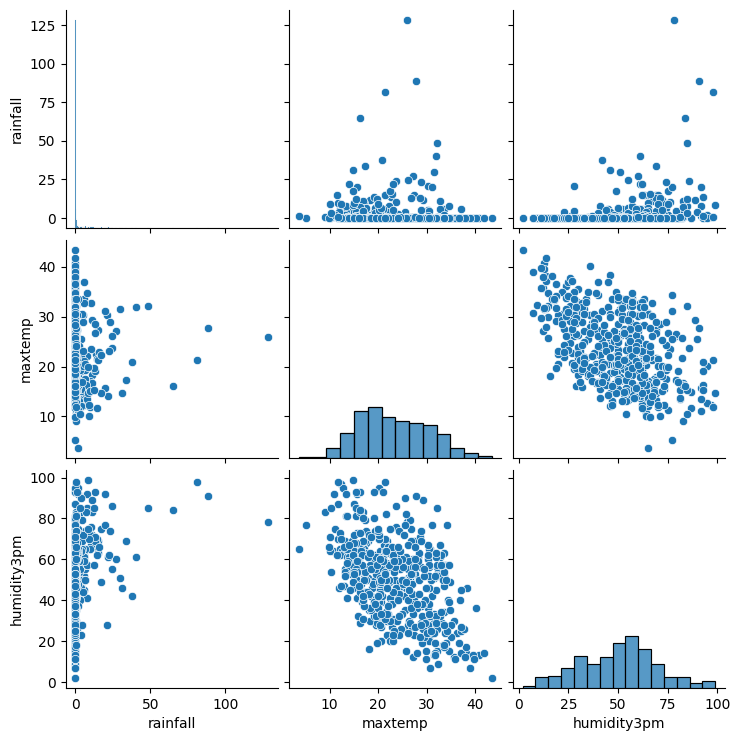

In [ ]:
features = ['rainfall', 'maxtemp', 'humidity3pm']
sns.pairplot(df[features].dropna().sample(min(500, len(df.dropna(subset=features))), random_state=1))
plt.show()

## Q36: High Correlation with Target Finder

In [ ]:
correlations = df.select_dtypes(include='number').corr()['rainfall']
print(correlations[abs(correlations) > 0.5])

rainfall         1.000000
high_rainfall    0.564629
Name: rainfall, dtype: float64


## Q37: Target Class Balance

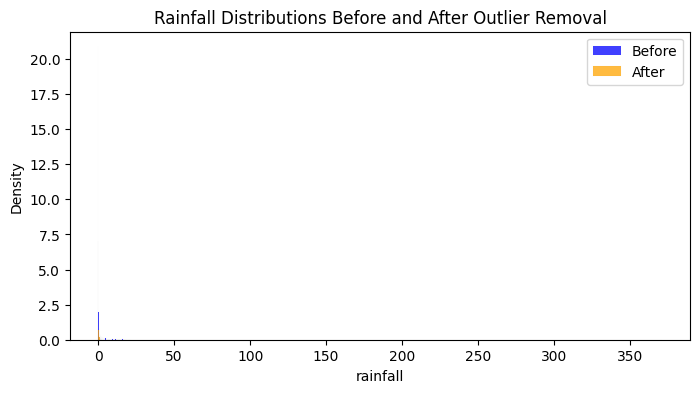

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['rainfall'], color='blue', label='Before', stat='density')
sns.histplot(df_clean['rainfall'], color='orange', label='After', stat='density')
plt.legend()
plt.title("Rainfall Distributions Before and After Outlier Removal")
plt.show()

## Q39: Feature Evaluation Summary Report

Shape: (145460, 24)
Missing: date                 0
location             0
mintemp           1485
maxtemp           1261
rainfall          3261
evaporation      62790
sunshine         69835
windgustdir      10326
windgustspeed    10263
winddir9am       10566
winddir3pm        4228
windspeed9am      1767
windspeed3pm      3062
humidity9am       2654
humidity3pm       4507
pressure9am      15065
pressure3pm      15028
cloud9am         55888
cloud3pm         59358
temp9am           1767
temp3pm           3609
raintoday         3261
raintomorrow      3267
high_rainfall        0
dtype: int64
Correlation:
                 mintemp   maxtemp  rainfall  evaporation  sunshine  \
mintemp        1.000000  0.736555  0.103938     0.466993  0.072586   
maxtemp        0.736555  1.000000 -0.074992     0.587932  0.470156   
rainfall       0.103938 -0.074992  1.000000    -0.064351 -0.227549   
evaporation    0.466993  0.587932 -0.064351     1.000000  0.365602   
sunshine       0.072586  0.470156 -0.22754

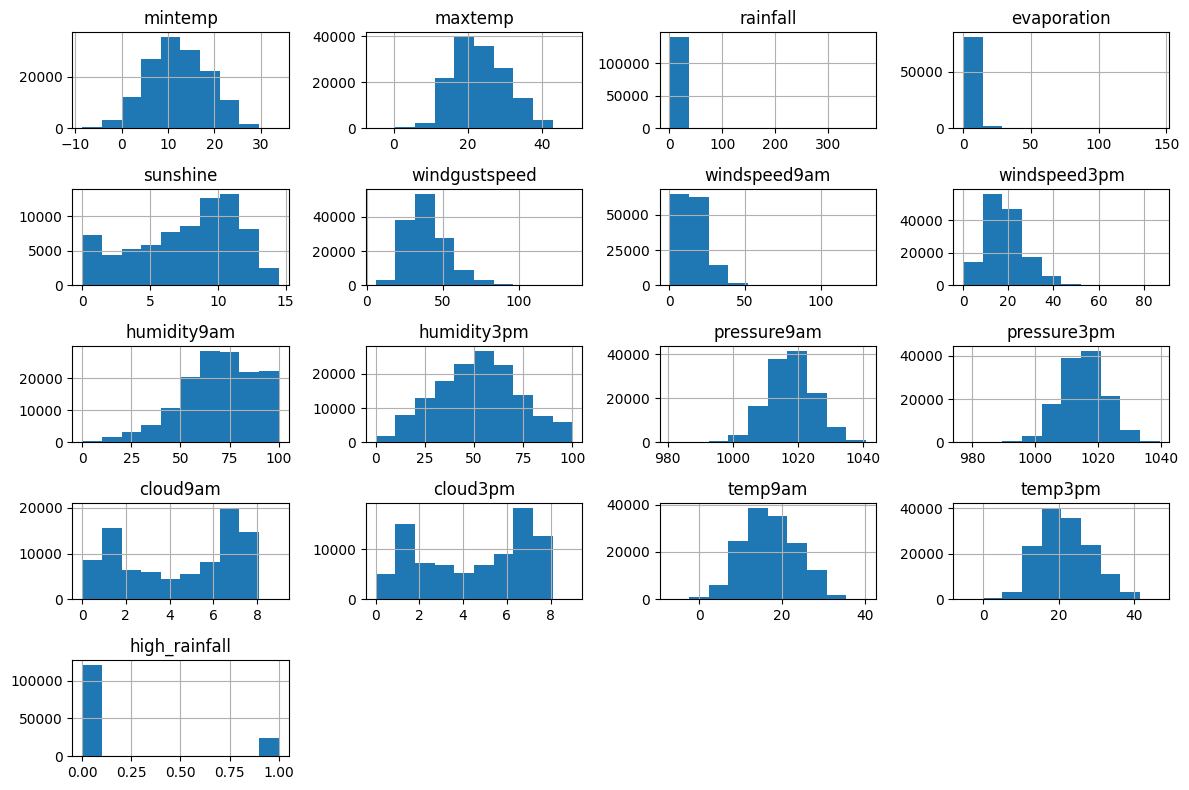

In [ ]:
def full_eda(data):
    print("Shape:", data.shape)
    print("Missing:", data.isnull().sum())
    numeric = data.select_dtypes(include='number')
    print("Correlation:\n", numeric.corr())
    numeric.hist(figsize=(12, 8))
    plt.tight_layout()
    plt.show()

full_eda(df)